# Lorenz–96: closure-based forecasting baseline
**Question:** Does the frozen closure combined with the known slow equations already predict the true multiscale slow dynamics accurately enough to serve as a strong forecasting baseline?

For **Test A**, compare these methods on identical real multiscale slow targets:
- The frozen GP closure plus numerical integration.
- Panda fine-tuned on multiscale slow observations.
- Panda fine-tuned on single-scale observations.

All methods receive the same observed slow history. Panda uses 512 points to directly predict the next 128. The reduced ODE starts from the final observed slow state and integrates the same 128 future times. No method receives fast states or future observations at inference.

A separate **single-scale restart control** checks the closure implementation and time alignment. Test B is outside this notebook.


## 1. What the closure provides
The full slow equation contains unresolved fast feedback:
$$
\dot x_k=f_k(x)+h_x\overline y_k.
$$
The reduced equation replaces the fast-group mean with the frozen local GP:
$$
\dot{\hat x}_k=f_k(\hat x)+h_x\widehat m(\hat x_k).
$$
The GP predicts a fast-group mean; `SingleScaleLorenz96` applies the factor \(h_x\). The closure alone is a feedback model. **The closure, known slow equations, and an ODE solver together form a complete forecast model.**

The GP was fitted on separate multiscale calibration data using fast-group means as training labels. The Panda checkpoints were fitted on forecasting training trajectories. This is a comparison of available forecasting workflows with different prior information, rather than a controlled comparison of architectures with identical training information.

Good performance on closure-generated single-scale data checks numerical self-consistency. Performance on true multiscale slow data measures the usefulness of the approximation for the actual forecasting task.


## 2. Environment and settings
Use the **panda** kernel. Closure integration runs in the existing **lorenz96_benchmark** environment, which created the frozen joblib artifact. This avoids loading a NumPy 2 random-state pickle in Panda's NumPy 1 environment. No closure refitting, conversion, or dependency changes are performed.

The second Python executable is detected as a sibling Conda environment. Change `closure_python` below if the environment is installed elsewhere. Model inputs use float32 as in the Panda evaluation; the ODE solver converts the same final observed values to float64.


In [1]:
import gc
from hashlib import sha256
from importlib.metadata import version
import json
import os
from pathlib import Path
import subprocess
import sys
from tempfile import TemporaryDirectory

project_root = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "src").is_dir() and (path / "data").is_dir()
)
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from tqdm.auto import tqdm

from src.evaluation import relative_l2_error
from src.models.baseline.panda import restore_panda_model

context_length = 512
prediction_length = 128
windows_per_trajectory = 6
window_seed = 99
batch_size = 6
model_parameters = {"K": 9, "hx": -0.8, "F": 10.0}
solver_settings = {"method": "DOP853", "rtol": 1e-8, "atol": 1e-10, "max_step": None}

data_root = project_root / "data" / "lorenz96_benchmark"
closure_path = data_root / "closure" / "a" / "closure.joblib"
closure_sha256 = sha256(closure_path.read_bytes()).hexdigest()
closure_env_dir = Path(sys.prefix).parent / "lorenz96_benchmark"
closure_python = closure_env_dir / ("python.exe" if os.name == "nt" else "bin/python")
if not closure_python.is_file():
    raise FileNotFoundError(f"Set closure_python to the benchmark environment's Python: {closure_python}")

training_root = project_root / "outputs" / "panda_lorenz96" / "training"
model_dirs = {
    "panda_multiscale": training_root / "multiscale_seed99" / "model",
    "panda_singlescale": training_root / "singlescale_seed99" / "model",
}
output_dir = project_root / "outputs" / "lorenz96_closure_baseline" / "test_a"
output_dir.mkdir(parents=True, exist_ok=True)

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
if device.type == "cpu":
    torch.set_num_threads(min(4, torch.get_num_threads()))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print(f"Panda device: {device}; closure Python: {closure_python}")
print({name: version(name) for name in ("torch", "numpy", "scipy", "scikit-learn")})


Panda device: cpu; closure Python: /opt/homebrew/Caskroom/miniconda/base/envs/lorenz96_benchmark/bin/python
{'torch': '2.13.0', 'numpy': '1.26.4', 'scipy': '1.17.1', 'scikit-learn': '1.9.1'}


## 3. Identical Test A windows
Use all 16 trajectories and the same six fixed-seed origins as `panda_lorenz96.ipynb`. Multiscale inputs come from `slow_downsampled/`; fast arrays are never loaded. The single-scale trajectories are used only for the restart control.

All methods receive the same float32 observations. Targets retain their saved float64 precision. Physical sampling intervals remain family-specific. No interpolation, time rescaling, or burn-in is applied to forecast windows.


In [2]:
trajectory_ids = [f"trajectory_{index:03d}" for index in range(1, 17)]
origins = np.stack([
    np.sort(np.random.default_rng(np.random.SeedSequence([window_seed, index])).choice(
        np.arange(context_length, 8192 - prediction_length + 1),
        size=windows_per_trajectory, replace=False,
    ))
    for index in range(len(trajectory_ids))
])

data = {}
for family in ("multiscale", "singlescale"):
    source = data_root / "test" / family / "a"
    observed_dir = source / "slow_downsampled" if family == "multiscale" else source
    paths = sorted(observed_dir.glob("trajectory_*.npz"))
    if [path.stem for path in paths] != trajectory_ids:
        raise ValueError(f"Expected all 16 Test A trajectories in {observed_dir}")
    contexts, targets, sample_intervals = [], [], []
    for index, path in enumerate(paths):
        record = json.loads((source / f"{path.stem}.json").read_text())
        if any(record["parameters"][key] != value for key, value in model_parameters.items()):
            raise ValueError(f"Unexpected Test A physical parameters in {path}")
        if family == "singlescale" and record["closure"]["sha256"] != closure_sha256:
            raise ValueError(f"The restart control must use the original frozen closure: {path}")
        sampling_record = json.loads(path.with_suffix(".json").read_text())
        sample_dt = sampling_record["sampling"]["sample_dt"]
        with np.load(path, allow_pickle=False) as archive:
            time = archive["time"]
            state = archive["slow_states"].T
        if state.shape != (8192, 9) or time.shape != (8192,) or not np.isfinite(state).all():
            raise ValueError(f"Unexpected Test A data in {path}")
        if not np.allclose(np.diff(time), sample_dt, rtol=1e-7, atol=0):
            raise ValueError(f"Sampling interval does not match the timestamps in {path}")
        contexts.append(np.stack([
            state[origin - context_length:origin] for origin in origins[index]
        ]).astype(np.float32))
        targets.append(np.stack([
            state[origin:origin + prediction_length] for origin in origins[index]
        ]))
        sample_intervals.append(sample_dt)
    if not np.allclose(sample_intervals, sample_intervals[0], rtol=1e-12, atol=0):
        raise ValueError("Test A trajectories must share a sampling interval within each family")
    data[family] = {
        "contexts": np.stack(contexts), "targets": np.stack(targets),
        "sample_dt": float(sample_intervals[0]),
    }

display(pd.DataFrame([
    {"Role": "Primary evaluation" if family == "multiscale" else "Numerical restart control",
     "Data": family, "Trajectories": 16, "Windows per trajectory": windows_per_trajectory,
     "Sample interval": values["sample_dt"],
     "Physical forecast horizon": prediction_length * values["sample_dt"]}
    for family, values in data.items()
]).set_index("Role"))
print("Example origins:", dict(zip(trajectory_ids[:3], origins[:3].tolist())))


Example origins: {'trajectory_001': [1854, 4332, 4378, 4779, 6232, 7744], 'trajectory_002': [4023, 4448, 5320, 5866, 6575, 6576], 'trajectory_003': [1473, 2405, 3039, 3481, 5631, 7690]}


,Data,Trajectories,Windows per trajectory,Sample interval,Physical forecast horizon
Role,,,,,
Primary evaluation,multiscale,16,6,0.014013,1.793722
Numerical restart control,singlescale,16,6,0.013470,1.724138


## 4. Restart the reduced ODE from observed states
The worker below uses the repository's `SingleScaleLorenz96` and `simulate_ode` directly. The reduced dynamics are autonomous, so each forecast uses a relative time origin of zero.

Request **129 samples including the initial state**, then discard sample 0. The remaining 128 states align with the next 128 held-out observations. `max_step=None` retains the library default of capping integration steps at the target sampling interval.

Also recompute one multiscale window with tighter tolerances and half the step cap. This checks that numerical integration error is small relative to the measured forecast error.


In [3]:
closure_worker = r"""
import json
from pathlib import Path
import sys
from time import perf_counter

import joblib
import numpy as np
import scipy
import sklearn

from src.data.lorenz96 import SingleScaleLorenz96, simulate_ode

input_path, output_path, closure_path, options_text = sys.argv[1:]
options = json.loads(options_text)
closure = joblib.load(closure_path)
model = SingleScaleLorenz96(closure=closure, **options["parameters"])
with np.load(input_path, allow_pickle=False) as archive:
    initial_states = archive["initial_states"]
    sample_intervals = archive["sample_intervals"]
predictions = np.empty((*initial_states.shape[:-1], options["prediction_length"], model.K))
start = perf_counter()
for family_index in range(len(initial_states)):
    for trajectory_index in range(initial_states.shape[1]):
        for window_index in range(initial_states.shape[2]):
            forecast = simulate_ode(
                model.rhs,
                initial_states[family_index, trajectory_index, window_index],
                sample_dt=float(sample_intervals[family_index]),
                n_samples=options["prediction_length"] + 1,
                t0=0.0, burn_in=0.0, **options["solver"],
            )
            # The initial observed state is not a prediction target
            predictions[family_index, trajectory_index, window_index] = forecast.state[:, 1:].T
        if (trajectory_index + 1) % 4 == 0:
            print(f"Closure family {family_index + 1}: {trajectory_index + 1}/16 trajectories", flush=True)

strict = simulate_ode(
    model.rhs, initial_states[0, 0, 0],
    sample_dt=float(sample_intervals[0]), n_samples=options["prediction_length"] + 1,
    method=options["solver"]["method"], rtol=1e-10, atol=1e-12,
    max_step=float(sample_intervals[0]) / 2,
).state[:, 1:].T
worker_record = {
    "python": sys.version.split()[0], "numpy": np.__version__,
    "scipy": scipy.__version__, "scikit-learn": sklearn.__version__,
    "closure_seconds": perf_counter() - start,
}
np.savez_compressed(
    output_path, predictions=predictions, strict_prediction=strict,
    worker_record=np.array(json.dumps(worker_record)),
)
"""


In [4]:
closure_options = {
    "parameters": model_parameters,
    "solver": solver_settings,
    "prediction_length": prediction_length,
}
closure_environment = dict(os.environ)
closure_environment.update(OPENBLAS_NUM_THREADS="1", OMP_NUM_THREADS="1", MKL_NUM_THREADS="1")

with TemporaryDirectory(prefix="lorenz96-closure-") as temporary:
    temporary = Path(temporary)
    input_path, prediction_path = temporary / "inputs.npz", temporary / "predictions.npz"
    np.savez(
        input_path,
        initial_states=np.stack([
            data[family]["contexts"][:, :, -1].astype(np.float64)
            for family in ("multiscale", "singlescale")
        ]),
        sample_intervals=np.array([data[family]["sample_dt"] for family in ("multiscale", "singlescale")]),
    )
    command = [
        str(closure_python), "-u", "-c", closure_worker,
        str(input_path), str(prediction_path), str(closure_path), json.dumps(closure_options),
    ]
    # Stream progress and any worker errors into the notebook
    with subprocess.Popen(
        command, cwd=project_root, env=closure_environment,
        stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
    ) as process:
        for line in process.stdout:
            print(line, end="", flush=True)
        return_code = process.wait()
    if return_code:
        raise RuntimeError(f"Closure integration failed with exit code {return_code}")
    with np.load(prediction_path, allow_pickle=False) as archive:
        closure_multiscale = archive["predictions"][0].copy()
        closure_singlescale = archive["predictions"][1].copy()
        strict_prediction = archive["strict_prediction"].copy()
        worker_record = json.loads(str(archive["worker_record"].item()))

if not np.isfinite(closure_multiscale).all() or not np.isfinite(closure_singlescale).all():
    raise ValueError("Closure forecasts must remain finite")
print("Closure environment:", worker_record)


Closure family 1: 4/16 trajectories
Closure family 1: 8/16 trajectories
Closure family 1: 12/16 trajectories
Closure family 1: 16/16 trajectories
Closure family 2: 4/16 trajectories
Closure family 2: 8/16 trajectories
Closure family 2: 12/16 trajectories
Closure family 2: 16/16 trajectories
Closure environment: {'python': '3.14.10', 'numpy': '2.5.4', 'scipy': '1.17.1', 'scikit-learn': '1.9.1', 'closure_seconds': 28.395311957923695}


## 5. Panda predictions on the same true slow targets
Restore each fine-tuned checkpoint together with its polynomial indices. Both models receive exactly the same multiscale slow contexts used to initialize the closure forecasts. No future targets enter the forward pass. Inference uses float32 without autocast.


In [5]:
predictions = {"closure": closure_multiscale}
for method, model_dir in model_dirs.items():
    model = restore_panda_model(
        checkpoint=model_dir,
        polynomial_indices_path=model_dir / "polynomial_indices.json",
        local_files_only=True,
    ).float().to(device).eval()
    if (model.config.context_length, model.config.prediction_length) != (context_length, prediction_length):
        raise ValueError(f"Unexpected checkpoint forecast lengths: {model_dir}")
    if model.config.distribution_output is not None:
        raise ValueError("This comparison expects deterministic Panda prediction heads")
    method_predictions = []
    for contexts in tqdm(data["multiscale"]["contexts"], desc=method, unit="trajectory"):
        batches = []
        with torch.inference_mode():
            for first in range(0, windows_per_trajectory, batch_size):
                past = torch.from_numpy(contexts[first:first + batch_size]).to(device)
                output = model(
                    past_values=past, past_observed_mask=torch.ones_like(past, dtype=torch.bool),
                    return_dict=True,
                ).prediction_outputs
                batches.append(output.cpu().numpy())
        method_predictions.append(np.concatenate(batches))
    predictions[method] = np.stack(method_predictions)
    del model, past, output
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()
    elif device.type == "mps":
        torch.mps.empty_cache()

for method, prediction in predictions.items():
    if prediction.shape != data["multiscale"]["targets"].shape or not np.isfinite(prediction).all():
        raise ValueError(f"Invalid prediction array for {method}")


panda_singlescale: 100%|##########| 16/16 [00:02<00:00,  7.04trajectory/s]


## 6. Relative L2 results on true multiscale slow data
Use `src.evaluation.relative_l2_error` for every score. Whole-window error reduces over all \(128\times9\) target entries. Per-lead error reduces over the nine channels.

Average the six windows within each trajectory first. Means and sample standard deviations below use the 16 trajectory-level values. Windows can overlap and are not treated as independent trajectories.


In [6]:
methods = {
    "closure": {"label": "Frozen GP closure + ODE", "color": "tab:green"},
    "panda_multiscale": {"label": "Panda trained on multiscale slow", "color": "tab:orange"},
    "panda_singlescale": {"label": "Panda trained on single-scale", "color": "tab:blue"},
}
metric_rows, error_curves = [], {}
targets = data["multiscale"]["targets"]
for method, spec in methods.items():
    window_errors = relative_l2_error(targets, predictions[method], axis=(-2, -1))
    lead_errors = relative_l2_error(targets, predictions[method], axis=-1)
    if not np.isfinite(window_errors).all() or not np.isfinite(lead_errors).all():
        raise ValueError("The summary requires finite relative L2 errors")
    error_curves[method] = lead_errors.mean(axis=1)
    for index, trajectory_id in enumerate(trajectory_ids):
        metric_rows.append({
            "Method": spec["label"], "Trajectory": trajectory_id,
            "Window relative L2": window_errors[index].mean(),
            "Lead 128 relative L2": lead_errors[index, :, -1].mean(),
        })

trajectory_metrics = pd.DataFrame(metric_rows)
summary = trajectory_metrics.groupby("Method", sort=False)[
    ["Window relative L2", "Lead 128 relative L2"]
].agg(["mean", "std"])
formatted_summary = pd.DataFrame(index=summary.index)
for metric in ("Window relative L2", "Lead 128 relative L2"):
    formatted_summary[metric] = [
        f"{mean:.6f} ± {std:.6f}"
        for mean, std in zip(summary[(metric, "mean")], summary[(metric, "std")])
    ]
display(formatted_summary)
print("Mean ± sample standard deviation across 16 trajectories; six windows per trajectory.")


Mean ± sample standard deviation across 16 trajectories; six windows per trajectory.


,Window relative L2,Lead 128 relative L2
Method,,
Frozen GP closure + ODE,0.093500 ± 0.029308,0.185212 ± 0.054161
Panda trained on multiscale slow,0.451635 ± 0.046320,0.594502 ± 0.066372
Panda trained on single-scale,0.477675 ± 0.054129,0.638484 ± 0.069677


## 7. Relative L2 versus forecast lead
All curves use the **same multiscale targets**. Lines show the median across 16 trajectory-level curves; shading shows the trajectory IQR. Each trajectory curve averages its six windows.


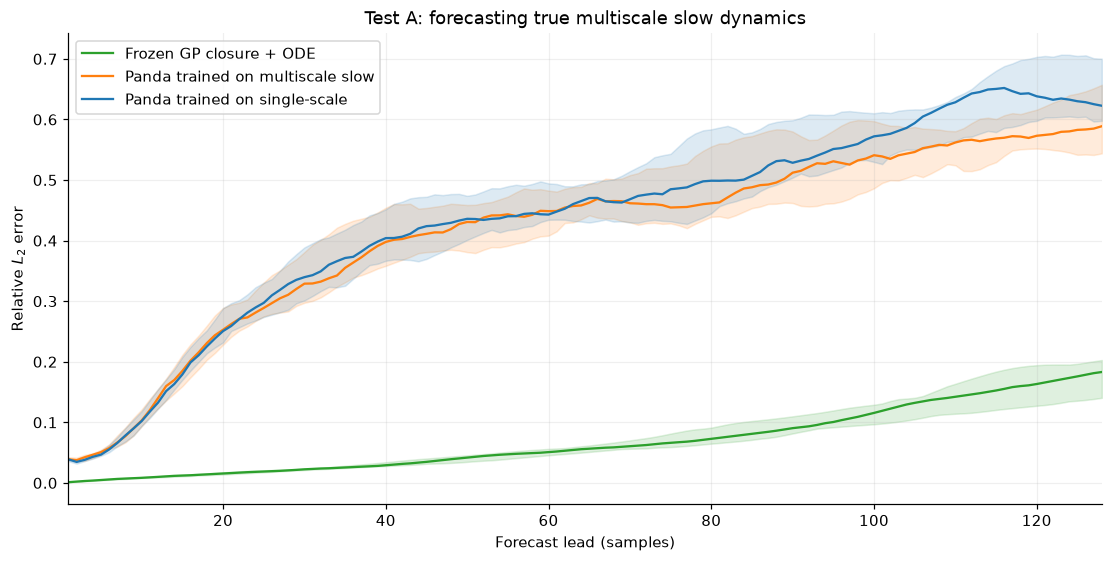

In [7]:
lead_times = np.arange(1, prediction_length + 1)
fig, axis = plt.subplots(figsize=(10, 5), constrained_layout=True)
for method, spec in methods.items():
    q25, median, q75 = np.quantile(error_curves[method], [0.25, 0.5, 0.75], axis=0)
    axis.plot(lead_times, median, color=spec["color"], label=spec["label"])
    axis.fill_between(lead_times, q25, q75, color=spec["color"], alpha=0.15)
axis.set(
    xlabel="Forecast lead (samples)", ylabel=r"Relative $L_2$ error",
    xlim=(1, prediction_length), title="Test A: forecasting true multiscale slow dynamics",
)
axis.grid(alpha=0.2)
axis.legend()
plt.show()


## 8. Representative forecasts
Use trajectory 001 and the first selected window, fixed before inspecting the errors. All methods predict the same future. Channels 0, 3, and 6 are shown for readability; every method predicts and is scored on all nine channels.


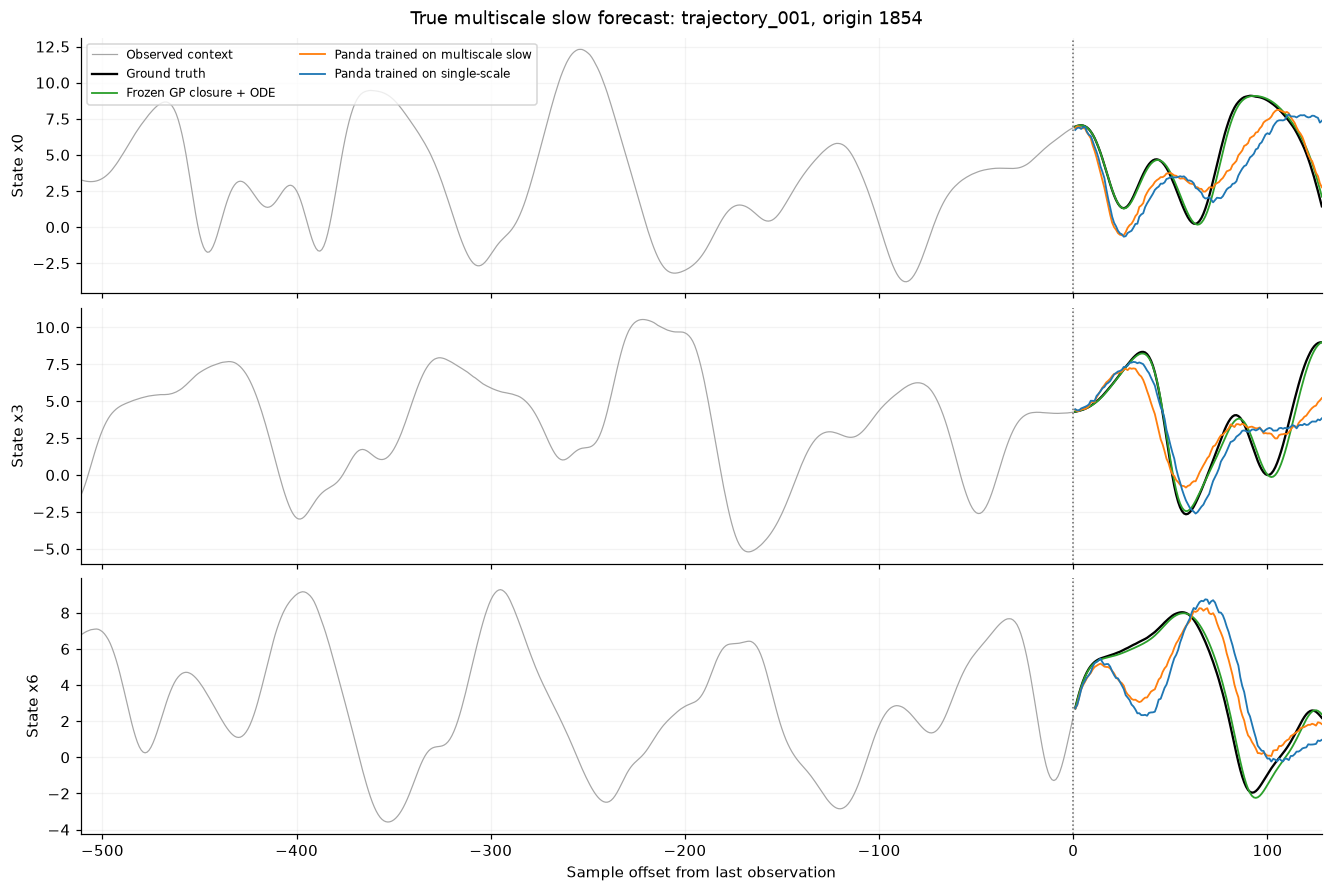

In [8]:
example_trajectory_index = 0
example_window_index = 0
context = data["multiscale"]["contexts"][example_trajectory_index, example_window_index]
target = targets[example_trajectory_index, example_window_index]
context_leads = np.arange(-context_length + 1, 1)

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True, constrained_layout=True)
for axis, channel in zip(axes, (0, 3, 6)):
    axis.plot(context_leads, context[:, channel], color="0.65", linewidth=0.8, label="Observed context")
    axis.plot(lead_times, target[:, channel], color="black", linewidth=1.5, label="Ground truth")
    for method, spec in methods.items():
        axis.plot(
            lead_times, predictions[method][example_trajectory_index, example_window_index, :, channel],
            color=spec["color"], linewidth=1.2, label=spec["label"],
        )
    axis.axvline(0, color="0.4", linestyle=":", linewidth=1)
    axis.set(ylabel=f"State x{channel}", xlim=(context_leads[0], prediction_length))
    axis.grid(alpha=0.15)
axes[0].legend(fontsize=8, ncol=2)
axes[-1].set_xlabel("Sample offset from last observation")
fig.suptitle(f"True multiscale slow forecast: trajectory_001, origin {origins[0, 0]}")
plt.show()


## 9. Numerical controls
**Single-scale restart:** the same frozen GP and reduced equations generated the single-scale targets. Restarting from the last observed state should reproduce the next 128 states to numerical accuracy. Small differences include float32 observation rounding and solver restart error.

**Solver refinement:** compare the default closure forecast with a tighter integration of the first multiscale window. This measures numerical sensitivity for that window, not the physical accuracy of the closure.


,Relative L2
Check,
Single-scale restart: mean window relative L2,1.044e-07
Single-scale restart: maximum window relative L2,7.986e-07
First multiscale window: default versus refined solver,2.497e-13


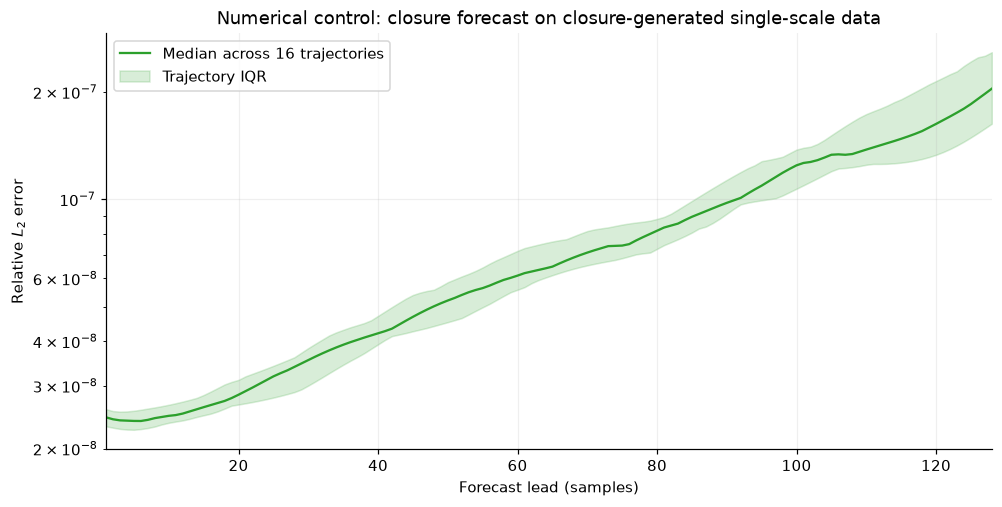

In [9]:
control_window_errors = relative_l2_error(
    data["singlescale"]["targets"], closure_singlescale, axis=(-2, -1)
)
control_lead_errors = relative_l2_error(
    data["singlescale"]["targets"], closure_singlescale, axis=-1
)
refinement_error = relative_l2_error(strict_prediction, closure_multiscale[0, 0])
control_table = pd.DataFrame([
    {"Check": "Single-scale restart: mean window relative L2",
     "Relative L2": control_window_errors.mean(axis=1).mean()},
    {"Check": "Single-scale restart: maximum window relative L2",
     "Relative L2": control_window_errors.max()},
    {"Check": "First multiscale window: default versus refined solver",
     "Relative L2": refinement_error},
]).set_index("Check")
display(control_table.style.format({"Relative L2": "{:.3e}"}))
if control_window_errors.max() > 1e-4:
    raise RuntimeError("The single-scale restart error is unexpectedly large; inspect closure, parameters, and alignment")

control_curves = control_lead_errors.mean(axis=1)
q25, median, q75 = np.quantile(control_curves, [0.25, 0.5, 0.75], axis=0)
fig, axis = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
axis.plot(lead_times, median, color="tab:green", label="Median across 16 trajectories")
axis.fill_between(lead_times, q25, q75, color="tab:green", alpha=0.18, label="Trajectory IQR")
axis.set(
    xlabel="Forecast lead (samples)", ylabel=r"Relative $L_2$ error",
    yscale="log", xlim=(1, prediction_length),
    title="Numerical control: closure forecast on closure-generated single-scale data",
)
axis.grid(alpha=0.2)
axis.legend()
plt.show()


## 10. Save and interpret
Save the actual forecasts, origins, summary, and settings under `outputs/lorenz96_closure_baseline/test_a/`. Rerunning replaces these files.

Interpret the primary multiscale results separately from the numerical control:
- A small single-scale restart error establishes self-consistency, not accuracy on true multiscale dynamics.
- If the closure ODE already forecasts true slow dynamics well, a learned surrogate needs to demonstrate a benefit in accuracy, cost, uncertainty, or observation handling.
- If the closure ODE has substantial error, investigate whether history-dependent prediction or sparse true observations can correct it.
- This comparison does not establish an architectural limit, a fair compute ranking, or the absence of useful fast-dynamics information. The closure baseline has known equations and fast-supervised calibration; Panda has a longer observed history.


In [10]:
np.savez_compressed(
    output_dir / "forecasts.npz",
    trajectory_ids=np.array(trajectory_ids), origins=origins,
    contexts=data["multiscale"]["contexts"], targets=targets,
    closure_predictions=predictions["closure"],
    panda_multiscale_predictions=predictions["panda_multiscale"],
    panda_singlescale_predictions=predictions["panda_singlescale"],
    single_scale_contexts=data["singlescale"]["contexts"],
    single_scale_targets=data["singlescale"]["targets"],
    single_scale_closure_predictions=closure_singlescale,
    strict_multiscale_prediction=strict_prediction,
)
summary.to_csv(output_dir / "summary.csv")
record = {
    "format_version": 1, "test_subset": "a",
    "settings": {
        "context_length": context_length, "prediction_length": prediction_length,
        "windows_per_trajectory": windows_per_trajectory, "window_seed": window_seed,
        "observation_dtype": "float32", "solver": solver_settings,
        "model_parameters": model_parameters,
    },
    "trajectories": trajectory_ids,
    "sample_intervals": {family: values["sample_dt"] for family, values in data.items()},
    "closure": {"path": str(closure_path.relative_to(project_root)), "sha256": closure_sha256},
    "panda_checkpoints": {
        method: {
            "path": str(path.relative_to(project_root)),
            "weights_sha256": sha256((path / "model.safetensors").read_bytes()).hexdigest(),
            "polynomial_indices_sha256": sha256((path / "polynomial_indices.json").read_bytes()).hexdigest(),
        }
        for method, path in model_dirs.items()
    },
    "closure_environment": worker_record,
    "panda_environment": {name: version(name) for name in ("torch", "numpy", "scipy", "scikit-learn")},
    "device": str(device),
    "numerical_checks": {
        "max_single_scale_window_relative_l2": float(control_window_errors.max()),
        "first_window_solver_refinement_relative_l2": float(refinement_error),
    },
}
(output_dir / "metadata.json").write_text(json.dumps(record, indent=2, allow_nan=False) + "\n")
display(formatted_summary)
best_method = summary[("Window relative L2", "mean")].idxmin()
print(f"Lowest mean window relative L2 on true multiscale slow Test A: {best_method}")
print(f"Saved forecasts and settings: {output_dir}")


Lowest mean window relative L2 on true multiscale slow Test A: Frozen GP closure + ODE
Saved forecasts and settings: /Users/yuhanzheng/PycharmProjects/MultiscaleDynamicsAI/outputs/lorenz96_closure_baseline/test_a


,Window relative L2,Lead 128 relative L2
Method,,
Frozen GP closure + ODE,0.093500 ± 0.029308,0.185212 ± 0.054161
Panda trained on multiscale slow,0.451635 ± 0.046320,0.594502 ± 0.066372
Panda trained on single-scale,0.477675 ± 0.054129,0.638484 ± 0.069677
